In [ ]:
"""Hardware execution for the four-qubit, two-electron H₂ fermionic HEA.

The notebook runs the supported hardware measurements and saves results and job IDs
in a separate output directory. Virtual distillation uses nine logical qubits and
requires substantially more circuits than the single-copy measurements."""

import os
import json
import time
import csv
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

from qiskit import QuantumCircuit, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector, Operator, SparsePauliOp
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

from benchmark.fermionic_hea import make_fermionic_hea, get_smooth_params
from nrep import (
    get_h2_sto3g_hamiltonian,
    jw_annihilation,
    rdm_operators,
    project_rdms_sdp,
    energy_general,
)


BACKEND_NAME = "ibm_marrakesh"  # Keep the same physical backend as the previous experiment; stop if unavailable.
N_QUBITS = 4
N_ELECTRONS = 2
HEA_DEPTH = 8
PARAMETER_SEED = 42

NREP_SHOTS = 2_048       # low-shot pilot: shots per QWC measurement group
ZNE_SHOTS = NREP_SHOTS    # ZNE uses the same per-group shot budget as the baseline
VD_SHOTS = 256            # low-shot pilot: shots per Hadamard-test circuit
OPTIMIZATION_LEVEL = 0  # Avoid cancelling local ZNE folds during transpilation
MAX_CIRCUITS_PER_JOB = 40
ENABLE_QPU_SUBMISSION = True  # Change to True only after offline preflight and dry run


OUTPUT_DIR = Path("ibm_hardware_qem_results_fresh")  # Fresh run; does not read or overwrite old results.
OUTPUT_DIR.mkdir(exist_ok=True)


service = QiskitRuntimeService()  # Uses saved IBM Quantum account

if BACKEND_NAME is None:
    raise RuntimeError("Set BACKEND_NAME explicitly. Automatic backend switching is disabled to keep this experiment comparable.")
backend = service.backend(BACKEND_NAME)
if not backend.status().operational:
    raise RuntimeError(
        f"Selected backend {BACKEND_NAME} is not operational. "
        "No alternate backend will be selected automatically."
    )
VD_BACKEND_COMPATIBLE = backend.num_qubits >= 9

sampler = Sampler(mode=backend)


h1, g2, e_nuc = get_h2_sto3g_hamiltonian()
n = N_QUBITS

a = jw_annihilation(n)
adag = [op.getH().tocsr() for op in a]
Hmat = np.zeros((2**n, 2**n), dtype=complex)

for p in range(n):
    for q in range(n):
        Hmat += h1[p, q] * (adag[p] @ a[q])

for p in range(n):
    for q in range(n):
        for r in range(n):
            for s in range(n):
                Hmat += 0.5 * g2[p, q, r, s] * (
                    adag[p] @ adag[q] @ a[s] @ a[r]
                )

Hmat += e_nuc * np.eye(2**n)
Hmat = (Hmat + Hmat.conj().T) / 2
H2 = SparsePauliOp.from_operator(Operator(Hmat)).simplify()

qc_parameterized = make_fermionic_hea(
    num_qubits=N_QUBITS,
    nelec=N_ELECTRONS,
    layers=HEA_DEPTH,
)
params = get_smooth_params(
    qc_parameterized, layer_depth=HEA_DEPTH, seed=PARAMETER_SEED
)
qc = qc_parameterized.assign_parameters(params)

ideal_energy = float(np.real(Statevector(qc).expectation_value(H2)))

def report_method_result(method_name, energy_hartree, measurement=None):
    """Print the same-circuit ideal reference, method result, absolute error and ratio."""
    energy_hartree = float(np.real(energy_hartree))
    abs_error_mha = abs(energy_hartree - ideal_energy) * 1000.0
    ratio = energy_hartree / ideal_energy if abs(ideal_energy) > 1e-15 else float("nan")
    print("\\n" + "=" * 58)
    print(f"{method_name} RESULT")
    print(f"Ideal same-circuit energy : {ideal_energy:.12f} Ha")
    print(f"{method_name} energy       : {energy_hartree:.12f} Ha")
    print(f"Absolute error             : {abs_error_mha:.6f} mHa")
    print(f"Energy ratio (E/E_ideal)   : {ratio:.10f}")
    print("=" * 58)


def pauli_decomposition(operator):
    """Return [(Qiskit Pauli label, coefficient)] for an operator."""
    spo = SparsePauliOp.from_operator(Operator(operator.toarray())).simplify()
    return [
        (label, complex(coeff))
        for label, coeff in zip(spo.paulis.to_labels(), spo.coeffs)
        if abs(coeff) > 1e-11
    ]

def qwc_compatible(a_label, b_label):
    """Qubit-wise commuting compatibility."""
    return all(
        a == "I" or b == "I" or a == b
        for a, b in zip(a_label, b_label)
    )

def greedy_qwc_groups(labels):
    """Greedy qubit-wise commuting grouping of Pauli strings."""
    groups = []
    for label in sorted(set(labels), key=lambda x: (-sum(p != "I" for p in x), x)):
        placed = False
        for group in groups:
            if all(qwc_compatible(label, other) for other in group):
                group.append(label)
                placed = True
                break
        if not placed:
            groups.append([label])
    return groups

def add_pauli_basis_rotations(circuit, label, qubit_offset=0):
    """Rotate Qiskit Pauli label q_(n-1)...q_0 to computational basis."""
    for q, pauli in enumerate(reversed(label)):
        physical_q = qubit_offset + q
        if pauli == "X":
            circuit.h(physical_q)
        elif pauli == "Y":
            circuit.sdg(physical_q)
            circuit.h(physical_q)

def parity_expectation_from_counts(counts, label):
    """Estimate a Pauli-string expectation from a full-register count map."""
    total = sum(counts.values())
    if total == 0:
        raise RuntimeError("Empty counts returned by backend.")
    active = [i for i, p in enumerate(reversed(label)) if p != "I"]
    accum = 0.0
    for bitstring, count in counts.items():
        bits = bitstring.replace(" ", "")
        parity = sum(bits[-1 - q] == "1" for q in active) % 2
        accum += (-1.0 if parity else 1.0) * count
    return float(accum / total)

ALL_JOB_RECORDS = []

results = {
    "backend": str(backend.name),
    "started_utc": datetime.now(timezone.utc).isoformat(),
    "run_type": "FRESH_RESULTS",
    "depth": HEA_DEPTH,
    "nrep_shots_per_group": NREP_SHOTS,
    "vd_shots_per_circuit": VD_SHOTS,
    "ideal_energy_hartree": ideal_energy,
}

RUN_SIGNATURE = {
    "backend": str(backend.name),
    "depth": HEA_DEPTH,
    "nrep_shots_per_group": NREP_SHOTS,
    "zne_shots_per_group": ZNE_SHOTS,
    "vd_shots_per_circuit": VD_SHOTS,
    "ideal_energy_hartree": round(float(ideal_energy), 12),
}
CHECKPOINT_PATH = OUTPUT_DIR / "summary_partial.json"
JOB_IDS_PATH = OUTPUT_DIR / "job_ids.json"

if CHECKPOINT_PATH.exists():
    with open(CHECKPOINT_PATH) as _f:
        _saved = json.load(_f)
    if _saved.get("_run_signature") != RUN_SIGNATURE:
        raise RuntimeError(
            "The fresh-run folder contains a different experiment configuration. "
            "Use a new output folder if you intentionally want a separate experiment."
        )
    results.update(_saved)
    def _strip_usage_fields(obj):
        _obsolete = {
            "qpu_time_budget_seconds", "qpu_time_used_seconds",
            "qpu_time_remaining_seconds", "qpu_time_accounting",
            "quantum_seconds", "qpu_time_metrics_error",
            "max_execution_time_seconds",
        }
        if isinstance(obj, dict):
            for _key in list(obj):
                if _key in _obsolete:
                    obj.pop(_key, None)
                else:
                    _strip_usage_fields(obj[_key])
        elif isinstance(obj, list):
            for _item in obj:
                _strip_usage_fields(_item)
    _strip_usage_fields(results)
    ALL_JOB_RECORDS = list(_saved.get("submitted_jobs", []))
    for _record in ALL_JOB_RECORDS:
        for _key in ("quantum_seconds", "qpu_time_metrics_error",
                     "max_execution_time_seconds"):
            _record.pop(_key, None)
elif JOB_IDS_PATH.exists():
    with open(JOB_IDS_PATH) as _f:
        ALL_JOB_RECORDS = list(json.load(_f))
    for _record in ALL_JOB_RECORDS:
        for _key in ("quantum_seconds", "qpu_time_metrics_error",
                     "max_execution_time_seconds"):
            _record.pop(_key, None)

def has_prior_job_tag(tag):
    return any(str(rec.get("tag", "")) == str(tag) for rec in ALL_JOB_RECORDS)

def save_checkpoint():
    results["_run_signature"] = RUN_SIGNATURE
    results["submitted_jobs"] = ALL_JOB_RECORDS
    with open(CHECKPOINT_PATH, "w") as f:
        json.dump(results, f, indent=2, default=str)
    with open(JOB_IDS_PATH, "w") as f:
        json.dump(ALL_JOB_RECORDS, f, indent=2)

def run_sampler_in_batches(circuits, shots, tag):
    """Submit circuits in sequential batches and retain job IDs for recovery."""
    all_counts = []
    job_records = []

    for start in range(0, len(circuits), MAX_CIRCUITS_PER_JOB):
        if not ENABLE_QPU_SUBMISSION:
            raise RuntimeError(
                "Hardware submission is disabled. Complete the offline preflight, "
                "then explicitly set ENABLE_QPU_SUBMISSION = True."
            )

        batch = circuits[start:start + MAX_CIRCUITS_PER_JOB]
        if any(
            str(rec.get("tag", "")) == str(tag)
            and int(rec.get("batch_start", -1)) == start
            for rec in ALL_JOB_RECORDS
        ):
            raise RuntimeError(
                f"Refusing duplicate submission for {tag}, batch_start={start}; "
                "a job with this tag is already recorded in this run."
            )

        print(f"{tag}: submitting circuits {start + 1}–{start + len(batch)} / {len(circuits)}")
        job = sampler.run(batch, shots=shots)
        job_id = job.job_id()
        record = {
            "tag": tag,
            "job_id": job_id,
            "batch_start": start,
            "batch_size": len(batch),
            "shots_per_circuit": shots,
        }
        job_records.append(record)
        ALL_JOB_RECORDS.append(record)
        save_checkpoint()

        try:
            result = job.result()
            for pub_result in result:
                all_counts.append(pub_result.data.meas.get_counts())
        except Exception as exc:
            record["job_result_error"] = repr(exc)
            save_checkpoint()
            raise RuntimeError(
                f"IBM Runtime job {job_id} did not complete successfully. "
                "Its job ID and diagnostic have been saved."
            ) from exc

    return all_counts, job_records


def measure_paulis_on_hardware(base_circuit, labels, shots, tag):
    """Measure a set of Pauli strings using QWC groups."""
    labels = sorted(set(labels))
    groups = greedy_qwc_groups(labels)
    circuits = []
    for group_index, group in enumerate(groups):
        basis = ["I"] * N_QUBITS
        for label in group:
            for q, p in enumerate(reversed(label)):
                if p != "I":
                    basis[q] = p

        meas = ClassicalRegister(N_QUBITS, "meas")
        measured = QuantumCircuit(N_QUBITS, name=f"{tag}_{group_index}")
        measured.add_register(meas)
        measured.compose(base_circuit, qubits=range(N_QUBITS), inplace=True)
        add_pauli_basis_rotations(measured, "".join(reversed(basis)))
        measured.measure(range(N_QUBITS), range(N_QUBITS))
        circuits.append(measured)

    compiled = transpile(
        circuits,
        backend=backend,
        optimization_level=OPTIMIZATION_LEVEL,
        seed_transpiler=PARAMETER_SEED,
    )
    print(f"{tag}: {len(labels)} Pauli strings -> {len(groups)} QWC groups")
    counts_list, jobs = run_sampler_in_batches(compiled, shots, tag)

    estimates = {}
    for group, counts in zip(groups, counts_list):
        for label in group:
            estimates[label] = parity_expectation_from_counts(counts, label)
    return estimates, {
        "num_paulis": len(labels),
        "num_qwc_groups": len(groups),
        "shots_per_group": shots,
        "jobs": jobs,
    }


O1, O2 = rdm_operators(N_QUBITS)
rdm_entries = []
rdm_labels = set()

for key, op in O1.items():
    terms = pauli_decomposition(op)
    rdm_entries.append(("1", key, terms))
    rdm_labels.update(label for label, _ in terms)

for key, op in O2.items():
    terms = pauli_decomposition(op)
    rdm_entries.append(("2", key, terms))
    rdm_labels.update(label for label, _ in terms)

hamiltonian_terms = [
    (label, complex(coeff))
    for label, coeff in zip(H2.paulis.to_labels(), H2.coeffs)
    if abs(coeff) > 1e-11
]
hamiltonian_labels = {label for label, _ in hamiltonian_terms}


def rdms_from_pauli_estimates(estimates):
    D1 = np.zeros((N_QUBITS, N_QUBITS), dtype=complex)
    D2_tensor = np.zeros(
        (N_QUBITS, N_QUBITS, N_QUBITS, N_QUBITS), dtype=complex
    )
    for kind, key, terms in rdm_entries:
        value = sum(coeff * estimates[label] for label, coeff in terms)
        if kind == "1":
            D1[key[0], key[1]] = value
        else:
            D2_tensor[key[0], key[1], key[2], key[3]] = value
    return D1, D2_tensor.reshape(N_QUBITS**2, N_QUBITS**2)

def raw_energy_from_rdms(D1, D2):
    return energy_general(h1, g2, D1, D2, e_nuc)

def apply_nrep(D1, D2):
    D1_projected, D2_projected = project_rdms_sdp(
        D1, D2, N_QUBITS, N_ELECTRONS, real=True
    )
    return energy_general(
        h1, g2, D1_projected, D2_projected, e_nuc
    )




def make_vd_hadamard_test(base_circuit, pauli_label=None):
    """
    Estimate Re Tr[(P rho^2)] for pauli_label=P, or Tr[rho^2] if None.

    Logical qubits:
      q0       : ancilla
      q1..q4   : copy A
      q5..q8   : copy B

    Controlled-SWAP followed by controlled-P on copy A implements
    U = (P_A tensor I_B) SWAP. The ancilla X expectation is the desired
    real Hadamard-test signal.
    """
    meas = ClassicalRegister(1, "meas")
    vd_circuit = QuantumCircuit(9, name="VD_SWAP" if pauli_label is None else f"VD_{pauli_label}")
    vd_circuit.add_register(meas)
    vd_circuit.compose(base_circuit, qubits=[1, 2, 3, 4], inplace=True)
    vd_circuit.compose(base_circuit, qubits=[5, 6, 7, 8], inplace=True)

    vd_circuit.h(0)
    for q in range(N_QUBITS):
        vd_circuit.cswap(0, 1 + q, 5 + q)

    if pauli_label is not None:
        for q, pauli in enumerate(reversed(pauli_label)):
            target = 1 + q
            if pauli == "X":
                vd_circuit.cx(0, target)
            elif pauli == "Y":
                vd_circuit.cy(0, target)
            elif pauli == "Z":
                vd_circuit.cz(0, target)

    vd_circuit.h(0)
    vd_circuit.measure(0, 0)
    return vd_circuit

def ancilla_expectation(counts):
    total = sum(counts.values())
    if total == 0:
        raise RuntimeError("Empty ancilla counts returned by backend.")
    return float(sum((1 if key.replace(" ", "")[-1] == "0" else -1) * val
                     for key, val in counts.items()) / total)

def run_vd_estimates(labels, tag):
    if not VD_BACKEND_COMPATIBLE:
        raise RuntimeError("Selected backend has fewer than 9 qubits; VD is unavailable on this backend.")
    labels = sorted(set(labels))
    circuits = [make_vd_hadamard_test(qc, None)]
    circuits += [make_vd_hadamard_test(qc, label) for label in labels]

    compiled = transpile(
        circuits,
        backend=backend,
        optimization_level=OPTIMIZATION_LEVEL,
        seed_transpiler=PARAMETER_SEED,
    )
    print(
        f"{tag}: {len(labels)} numerator circuits + 1 denominator circuit; "
        f"{VD_SHOTS} shots each"
    )
    counts_list, jobs = run_sampler_in_batches(compiled, VD_SHOTS, tag)
    purity = ancilla_expectation(counts_list[0])
    if purity <= 1e-6:
        raise RuntimeError(
            f"Measured purity denominator is too small ({purity}). "
            "VD ratio would be statistically unstable."
        )

    vd_values = {}
    for label, counts in zip(labels, counts_list[1:]):
        numerator = ancilla_expectation(counts)
        vd_values[label] = numerator / purity

    return vd_values, purity, {
        "num_numerator_paulis": len(labels),
        "num_circuits_including_denominator": len(circuits),
        "shots_per_circuit": VD_SHOTS,
        "measured_purity": purity,
        "jobs": jobs,
    }

In [ ]:
Hmat_check = H2.to_matrix()
assert np.allclose(Hmat_check, Hmat_check.conj().T, atol=1e-9), "H2 is not Hermitian."
psi_check = np.asarray(Statevector(qc).data)
prob_check = np.abs(psi_check) ** 2
sector_prob = sum(prob_check[idx] for idx in range(2**N_QUBITS) if idx.bit_count() == N_ELECTRONS)
assert abs(sector_prob - 1.0) < 1e-8, (
    f"Ansatz does not remain in N={N_ELECTRONS} sector: probability={sector_prob}"
)
E_sector_fci_check = fci_energy_in_fixed_particle_sector(H2, N_ELECTRONS) if "fci_energy_in_fixed_particle_sector" in globals() else None
from nrep import exact_rdms, energy_general
rho_ideal_check = np.outer(psi_check, psi_check.conj())
D1_exact_check, D2_exact_check = exact_rdms(rho_ideal_check, N_QUBITS)
E_from_rdms_check = float(np.real(energy_general(h1, g2, D1_exact_check, D2_exact_check, e_nuc)))
rdm_energy_delta = abs(E_from_rdms_check - ideal_energy)
assert rdm_energy_delta < 1e-7, (
    f"RDM/Hamiltonian convention mismatch: statevector={ideal_energy:.12f}, "
    f"RDM contraction={E_from_rdms_check:.12f}, delta={rdm_energy_delta:.3e}"
)
from zne import fold_gates_local

def fold_for_hardware(circuit, scale):
    """Normalize fold_gates_local outputs across the user's module versions.

    Supported returns:
      - QuantumCircuit
      - (QuantumCircuit, effective_scale)
      - tuples with additional metadata, including a 3-item return
    """
    raw = fold_gates_local(circuit, scale)
    if isinstance(raw, QuantumCircuit):
        return raw, float(scale)
    if isinstance(raw, tuple):
        circuit_candidates = [item for item in raw if isinstance(item, QuantumCircuit)]
        if len(circuit_candidates) != 1:
            raise TypeError(
                "fold_gates_local must return exactly one QuantumCircuit; "
                f"received tuple with {len(circuit_candidates)} circuit candidates."
            )
        numeric_candidates = []
        for item in raw:
            if isinstance(item, (int, float, np.integer, np.floating)) and np.isfinite(item):
                numeric_candidates.append(float(item))
        effective = min(numeric_candidates, key=lambda x: abs(x - float(scale))) if numeric_candidates else float(scale)
        return circuit_candidates[0], effective
    raise TypeError(
        "Unsupported fold_gates_local return type: " + type(raw).__name__
    )

qc_fold_check, effective_fold_check = fold_for_hardware(qc, 3)
E_fold_check = float(np.real(Statevector(qc_fold_check).expectation_value(H2)))
fold_delta = abs(E_fold_check - ideal_energy)
assert fold_delta < 1e-8, (
    f"ZNE folding changed the ideal unitary: energy delta={fold_delta:.3e}"
)







In [3]:
if "Noisy" not in results and has_prior_job_tag("NOISY_H2_REFERENCE"):
    print("A noisy-baseline job is already recorded but no completed energy is checkpointed. Not resubmitting.")
elif "Noisy" not in results:
    noisy_h_estimates, noisy_h_diag = measure_paulis_on_hardware(
        qc, hamiltonian_labels, NREP_SHOTS, "NOISY_H2_REFERENCE"
    )
    noisy_energy = float(np.real(sum(
        coeff * noisy_h_estimates[label] for label, coeff in hamiltonian_terms
    )))
    results["Noisy"] = {"energy_hartree": noisy_energy, "measurement": noisy_h_diag,
                        "status": "COMPLETED"}
    results["noisy_hamiltonian_pauli_expectations"] = noisy_h_estimates
    save_checkpoint()
    report_method_result("Noisy baseline", noisy_energy, noisy_h_diag)
else:
    noisy_energy = results["Noisy"]["energy_hartree"]
    print("Reusing noisy baseline:", noisy_energy)
    report_method_result("Noisy baseline", noisy_energy, results["Noisy"].get("measurement"))

A noisy-baseline job is already recorded but no completed energy is checkpointed. Not resubmitting.


In [4]:
from zne import fold_gates_local, richardson_extrapolation
ZNE_SCALES = [1.0, 3.0]
assert all(float(s).is_integer() and int(s) % 2 == 1 for s in ZNE_SCALES), "Use odd integer local-folding scales only."
assert "ZNE_SHOTS" in globals() and ZNE_SHOTS > 0
assert "measure_paulis_on_hardware" in globals()
if not ENABLE_QPU_SUBMISSION:
    print("ZNE not submitted: ENABLE_QPU_SUBMISSION=False.")
elif "ZNE" not in results and any(has_prior_job_tag(f"ZNE_SCALE_{s:g}") for s in ZNE_SCALES):
    print("A prior ZNE scale job is recorded without a completed extrapolated result. Not resubmitting.")
elif "ZNE" not in results:
    zne_vals, zne_diags, effective_scales = [], [], []
    for scale in ZNE_SCALES:
        if scale == 1:
            folded, effective_scale = qc.copy(), 1.0
        else:
            folded, effective_scale = fold_for_hardware(qc, int(scale))
        est, diag = measure_paulis_on_hardware(
            folded, hamiltonian_labels, ZNE_SHOTS, f"ZNE_SCALE_{scale:g}"
        )
        energy = float(np.real(sum(coeff * est[label] for label, coeff in hamiltonian_terms)))
        zne_vals.append(energy)
        zne_diags.append(diag)
        effective_scales.append(float(effective_scale))
        print(f"nominal scale={scale:g}; effective scale={effective_scale:.3f}: E={energy:.10f} Ha")
    zne_energy, zne_weights = richardson_extrapolation(
        np.asarray(effective_scales, float), np.asarray(zne_vals, float)
    )
    results["ZNE"] = {
        "energy_hartree": float(zne_energy),
        "scale_factors": ZNE_SCALES,
        "effective_scale_factors": effective_scales,
        "scale_energies_hartree": zne_vals,
        "richardson_weights": np.asarray(zne_weights).tolist(),
        "measurement": zne_diags,
        "status": "COMPLETED",
    }
    save_checkpoint()
    report_method_result("ZNE", zne_energy, zne_diags)
else:
    print("ZNE already present in this fresh session; skipping.")
    report_method_result("ZNE", results["ZNE"]["energy_hartree"], results["ZNE"].get("measurement"))

ZNE_SCALE_1: 19 Pauli strings -> 9 QWC groups
ZNE_SCALE_1: submitting circuits 1–9 / 9
nominal scale=1; effective scale=1.000: E=-0.4704259960 Ha
ZNE_SCALE_3: 19 Pauli strings -> 9 QWC groups
ZNE_SCALE_3: submitting circuits 1–9 / 9
nominal scale=3; effective scale=3.000: E=-0.0274633915 Ha
\n==========================================================
ZNE RESULT
Ideal same-circuit energy : -0.843912508933 Ha
ZNE energy       : -0.691907298211 Ha
Absolute error             : 152.005211 mHa
Energy ratio (E/E_ideal)   : 0.8198803678


In [ ]:
from mem import MEMitigator
results["MEM"] = {
    "status": "NOT_HARDWARE_IMPLEMENTED",
    "reason": "Original MEMitigator.calibrate/run use AerSimulator. A valid IBM adapter must calibrate assignment matrices on the same physical qubits and invert each QWC group's joint bitstring distribution. The previous scalar-expectation scaffold is not used."
}
print(results["MEM"])

In [ ]:
from svxx import SymmetryVerifiedMitigator
results["SV"] = {
    "status": "NOT_HARDWARE_IMPLEMENTED",
    "reason": "The uploaded routine filters only a two-qubit XX sector and extracts one ZZ expectation. It cannot be applied to the four-qubit H2 Hamiltonian or certify N=2."
}
print(results["SV"])

In [5]:
from pc_vd import VDMitigator
RUN_VD = True  # Enable only after checking the full 9-qubit circuit/job cost.
if not ENABLE_QPU_SUBMISSION or not RUN_VD:
    print("Hardware VD skipped. It needs 9 logical qubits and one circuit per Pauli term plus a denominator.")
elif "VD" in results and results["VD"].get("energy_hartree") is not None:
    print("VD already completed in this fresh session; skipping duplicate submission.")
    report_method_result("VD", results["VD"]["energy_hartree"], results["VD"].get("measurement"))
elif has_prior_job_tag("VD_H2"):
    print("A prior VD job is recorded without a completed energy. Not resubmitting.")
else:
    try:
        vd_h_estimates, vd_purity, vd_diag = run_vd_estimates(hamiltonian_labels, "VD_H2")
        if not np.isfinite(vd_purity) or vd_purity <= 1e-6:
            results["VD"] = {
                "status": "UNSTABLE_DENOMINATOR",
                "purity": float(vd_purity),
                "measurement": vd_diag,
                "reason": "Measured purity denominator is non-positive or too small; no VD energy reported."
            }
            save_checkpoint()
            print(f"VD skipped: measured purity={vd_purity:.6f}; denominator is statistically unstable.")
        else:
            vd_energy = float(np.real(sum(coeff * vd_h_estimates[label] for label, coeff in hamiltonian_terms)))
            results["VD"] = {"energy_hartree": vd_energy, "purity": float(vd_purity),
                             "measurement": vd_diag, "status": "COMPLETED"}
            save_checkpoint()
            report_method_result("VD", vd_energy, vd_diag)
    except Exception as exc:
        results["VD"] = {"status": "FAILED_OR_INCOMPLETE", "reason": repr(exc)}
        save_checkpoint()
        print("VD failed; notebook can continue. Inspect the saved job IDs before deciding whether to retry.")
        print("Diagnostic:", repr(exc))

VD_H2: 19 numerator circuits + 1 denominator circuit; 256 shots each
VD_H2: submitting circuits 1–20 / 20
\n==========================================================
VD RESULT
Ideal same-circuit energy : -0.843912508933 Ha
VD energy       : -0.178016111417 Ha
Absolute error             : 665.896398 mHa
Energy ratio (E/E_ideal)   : 0.2109414300


In [ ]:
from senew import SEMitigator, default_single_qubit_pool
se_pool = default_single_qubit_pool(N_QUBITS)
results["SE"] = {
    "status": "NOT_HARDWARE_IMPLEMENTED",
    "operator_pool_size": len(se_pool),
    "reason": "Hardware SE requires measured overlap S_ij=<P_i†P_j> and Hamiltonian H_ij=<P_i†HP_j> matrices. The supplied run() constructs these from an Aer density matrix."
}
print(results["SE"])

In [6]:
from nrep import project_rdms_sdp, energy_general, get_h2_sto3g_hamiltonian
if not ENABLE_QPU_SUBMISSION:
    print("NRep not submitted: ENABLE_QPU_SUBMISSION=False.")
elif "NRep" not in results and has_prior_job_tag("NREP_H2_RDM"):
    print("NRep tomography jobs are already recorded without a completed energy. Not resubmitting.")
elif "NRep" not in results:
    try:
        estimates, diag = measure_paulis_on_hardware(qc, rdm_labels, NREP_SHOTS, "NREP_H2_RDM")
        D1_raw, D2_raw = rdms_from_pauli_estimates(estimates)
        E_raw = float(np.real(raw_energy_from_rdms(D1_raw, D2_raw)))
        D1_proj, D2_proj = project_rdms_sdp(D1_raw, D2_raw, N_QUBITS, N_ELECTRONS, real=True)
        E_proj = float(np.real(energy_general(h1, g2, D1_proj, D2_proj, e_nuc)))
        results["NRep"] = {
            "raw_energy_hartree": E_raw,
            "energy_hartree": E_proj,
            "measurement": diag,
            "total_shots": diag["num_qwc_groups"] * NREP_SHOTS,
            "status": "COMPLETED",
        }
        save_checkpoint()
        print(f"NRep raw energy: {E_raw:.10f} Ha")
        report_method_result("NRep", E_proj, diag)
    except Exception as exc:
        results["NRep"] = {"status": "FAILED_OR_INCOMPLETE", "reason": repr(exc)}
        save_checkpoint()
        print("NRep failed; no automatic retry is performed.")
        print("Diagnostic:", repr(exc))
else:
    print("NRep already present in this fresh session; skipping.")
    report_method_result("NRep", results["NRep"]["energy_hartree"], results["NRep"].get("measurement"))

NREP_H2_RDM: 99 Pauli strings -> 44 QWC groups
NREP_H2_RDM: submitting circuits 1–40 / 44
NREP_H2_RDM: submitting circuits 41–44 / 44
NRep raw energy: -0.4551258103 Ha
\n==========================================================
NRep RESULT
Ideal same-circuit energy : -0.843912508933 Ha
NRep energy       : -0.693576038321 Ha
Absolute error             : 150.336471 mHa
Energy ratio (E/E_ideal)   : 0.8218577530


In [7]:
RUN_VD_NREP = True  # Optional; very large two-copy workload.
if not RUN_VD_NREP or not ENABLE_QPU_SUBMISSION:
    print("VD + NRep skipped (RUN_VD_NREP=False or QPU submission disabled).")
elif "VD + NRep" in results and results["VD + NRep"].get("energy_hartree") is not None:
    report_method_result("VD + NRep", results["VD + NRep"]["energy_hartree"],
                         results["VD + NRep"].get("measurement"))
else:
    try:
        vd_rdm_est, vd_rdm_purity, vd_rdm_diag = run_vd_estimates(rdm_labels, "VD_NREP_RDM")
        if not np.isfinite(vd_rdm_purity) or vd_rdm_purity <= 1e-6:
            results["VD + NRep"] = {
                "status": "UNSTABLE_DENOMINATOR",
                "purity": float(vd_rdm_purity),
                "measurement": vd_rdm_diag,
                "reason": "Measured purity denominator is statistically unstable; no combined energy reported."
            }
            save_checkpoint()
            print(f"VD + NRep skipped: measured purity={vd_rdm_purity:.6f}.")
        else:
            D1_vd, D2_vd = rdms_from_pauli_estimates(vd_rdm_est)
            D1_vd_p, D2_vd_p = project_rdms_sdp(D1_vd, D2_vd, N_QUBITS, N_ELECTRONS, real=True)
            E_vd_nrep = float(np.real(energy_general(h1, g2, D1_vd_p, D2_vd_p, e_nuc)))
            results["VD + NRep"] = {
                "energy_hartree": E_vd_nrep, "purity": float(vd_rdm_purity),
                "measurement": vd_rdm_diag, "status": "COMPLETED"
            }
            save_checkpoint()
            report_method_result("VD + NRep", E_vd_nrep, vd_rdm_diag)
    except Exception as exc:
        results["VD + NRep"] = {"status": "FAILED_OR_INCOMPLETE", "reason": repr(exc)}
        save_checkpoint()
        print("VD + NRep failed; no automatic retry is performed.")
        print("Diagnostic:", repr(exc))

VD_NREP_RDM: 99 numerator circuits + 1 denominator circuit; 256 shots each
VD_NREP_RDM: submitting circuits 1–40 / 100
VD_NREP_RDM: submitting circuits 41–80 / 100
VD_NREP_RDM: submitting circuits 81–100 / 100
\n==========================================================
VD + NRep RESULT
Ideal same-circuit energy : -0.843912508933 Ha
VD + NRep energy       : -0.444294482494 Ha
Absolute error             : 399.618026 mHa
Energy ratio (E/E_ideal)   : 0.5264698387


In [8]:
RUN_ZNE_NREP = True  # Optional; substantial additional usage.
if not RUN_ZNE_NREP or not ENABLE_QPU_SUBMISSION:
    print("ZNE + NRep skipped (RUN_ZNE_NREP=False or QPU submission disabled).")
elif "ZNE + NRep" in results and results["ZNE + NRep"].get("energy_hartree") is not None:
    report_method_result("ZNE + NRep", results["ZNE + NRep"]["energy_hartree"],
                         results["ZNE + NRep"].get("measurement"))
else:
    try:
        zne_nrep_energies, zne_nrep_diagnostics, effective_scales = [], [], []
        for scale in ZNE_SCALES:
            if scale == 1:
                folded, effective_scale = qc.copy(), 1.0
            else:
                folded, effective_scale = fold_for_hardware(qc, int(scale))
            rdm_est, rdm_diag = measure_paulis_on_hardware(
                folded, rdm_labels, NREP_SHOTS, f"ZNE_NREP_SCALE_{scale:g}"
            )
            d1m, d2m = rdms_from_pauli_estimates(rdm_est)
            d1p, d2p = project_rdms_sdp(d1m, d2m, N_QUBITS, N_ELECTRONS, real=True)
            e_scale = float(np.real(energy_general(h1, g2, d1p, d2p, e_nuc)))
            zne_nrep_energies.append(e_scale)
            zne_nrep_diagnostics.append(rdm_diag)
            effective_scales.append(float(effective_scale))
            print(f"ZNE+NRep nominal={scale:g}; effective={effective_scale:.3f}: {e_scale:.10f} Ha")
        e_combined, weights = richardson_extrapolation(
            np.asarray(effective_scales, float), np.asarray(zne_nrep_energies, float)
        )
        results["ZNE + NRep"] = {
            "energy_hartree": float(e_combined),
            "scale_factors": ZNE_SCALES,
            "effective_scale_factors": effective_scales,
            "scale_energies_hartree": zne_nrep_energies,
            "richardson_weights": np.asarray(weights).tolist(),
            "measurement": zne_nrep_diagnostics,
            "status": "COMPLETED",
            "note": "NRep SDP applied at each noise scale, followed by Richardson extrapolation."
        }
        save_checkpoint()
        report_method_result("ZNE + NRep", e_combined, zne_nrep_diagnostics)
    except Exception as exc:
        results["ZNE + NRep"] = {"status": "FAILED_OR_INCOMPLETE", "reason": repr(exc)}
        save_checkpoint()
        print("ZNE + NRep failed; no automatic retry is performed.")
        print("Diagnostic:", repr(exc))

ZNE_NREP_SCALE_1: 99 Pauli strings -> 44 QWC groups
ZNE_NREP_SCALE_1: submitting circuits 1–40 / 44
ZNE_NREP_SCALE_1: submitting circuits 41–44 / 44
ZNE+NRep nominal=1; effective=1.000: -0.6801530451 Ha
ZNE_NREP_SCALE_3: 99 Pauli strings -> 44 QWC groups
ZNE_NREP_SCALE_3: submitting circuits 1–40 / 44
ZNE_NREP_SCALE_3: submitting circuits 41–44 / 44
ZNE+NRep nominal=3; effective=3.000: -0.4332555176 Ha
\n==========================================================
ZNE + NRep RESULT
Ideal same-circuit energy : -0.843912508933 Ha
ZNE + NRep energy       : -0.803601808828 Ha
Absolute error             : 40.310700 mHa
Energy ratio (E/E_ideal)   : 0.9522335554


Base preparation circuit: 96 transpiled two-qubit gates
Ideal same-circuit energy: -0.843912508933 Ha


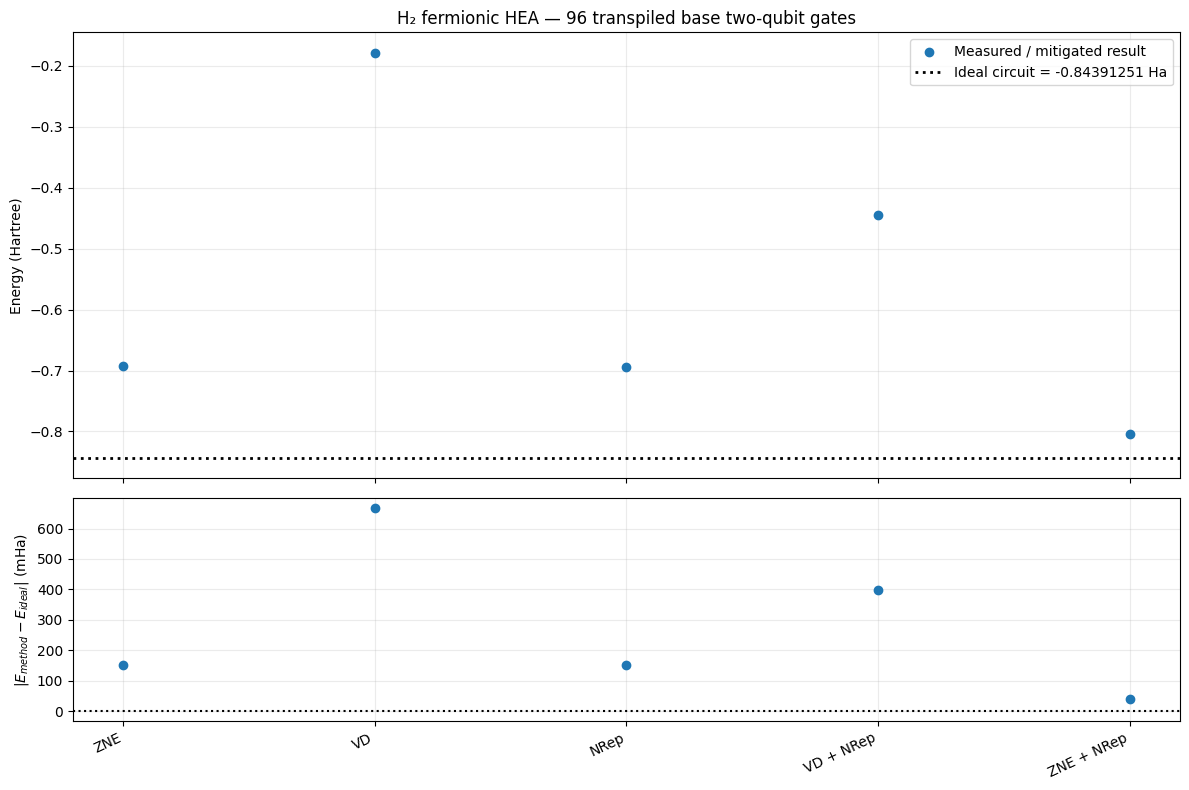

,method,energy_hartree,absolute_error_mHa,energy_ratio_E_over_ideal
0,Ideal,-0.843913,0.000000,1.000000
1,ZNE,-0.691907,152.005211,0.819880
2,VD,-0.178016,665.896398,0.210941
3,NRep,-0.693576,150.336471,0.821858
4,VD + NRep,-0.444294,399.618026,0.526470
5,ZNE + NRep,-0.803602,40.310700,0.952234


Fresh-run outputs saved in: /home/jovyan/QEM/ibm_hardware_qem_results_fresh


In [9]:
import matplotlib.pyplot as plt

def fci_energy_in_fixed_particle_sector(H_sparsepauli, nelec):
    Hm = np.asarray(H_sparsepauli.to_matrix(), dtype=complex)
    basis = [idx for idx in range(Hm.shape[0]) if int(idx).bit_count() == nelec]
    block = Hm[np.ix_(basis, basis)]
    return float(np.linalg.eigvalsh((block + block.conj().T) / 2).min().real)

E_IDEAL = float(np.real(Statevector(qc).expectation_value(H2)))
base_transpiled = transpile(
    qc, backend=backend, optimization_level=0, seed_transpiler=PARAMETER_SEED
)
base_2q = sum(
    int(count) for name, count in base_transpiled.count_ops().items()
    if name in {"cx", "ecr", "cz", "iswap", "rxx", "rzz", "cy", "ch", "cs"}
)
print(f"Base preparation circuit: {base_2q} transpiled two-qubit gates")
print(f"Ideal same-circuit energy: {E_IDEAL:.12f} Ha")

plot_rows = []
if isinstance(results.get("Noisy"), dict):
    val = results["Noisy"].get("energy_hartree")
    if val is not None and np.isfinite(val):
        plot_rows.append(("Noisy", float(val)))

method_order = ["ZNE", "MEM", "SV", "VD", "SE", "NRep", "VD + NRep", "ZNE + NRep", "PEC"]
for method in method_order:
    item = results.get(method)
    if isinstance(item, dict):
        val = item.get("energy_hartree")
        if val is not None and np.isfinite(val):
            plot_rows.append((method, float(val)))

plot_names = [name for name, _ in plot_rows]
plot_values = [value for _, value in plot_rows]
x = np.arange(len(plot_names))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)
if len(plot_rows):
    ax1.scatter(x, plot_values, label="Measured / mitigated result", zorder=3)
    errors_mha = np.abs(np.asarray(plot_values) - E_IDEAL) * 1000.0
    ax2.scatter(x, errors_mha, label="Absolute error", zorder=3)

ax1.axhline(E_IDEAL, linestyle=":", linewidth=2, color="black",
            label=f"Ideal circuit = {E_IDEAL:.8f} Ha")
ax1.set_ylabel("Energy (Hartree)")
ax1.set_title(f"H₂ fermionic HEA — {base_2q} transpiled base two-qubit gates")
ax1.grid(alpha=0.25)
ax1.legend()

ax2.axhline(0.0, linestyle=":", linewidth=1.5, color="black")
ax2.set_ylabel(r"$|E_{method}-E_{ideal}|$ (mHa)")
ax2.set_xticks(x)
ax2.set_xticklabels(plot_names, rotation=25, ha="right")
ax2.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "H2_QEM_two_panel_fresh.png", dpi=220, bbox_inches="tight")
plt.show()

table_rows = [{
    "method": "Ideal",
    "energy_hartree": E_IDEAL,
    "absolute_error_mHa": 0.0,
    "energy_ratio_E_over_ideal": 1.0,
}]
for method, energy in plot_rows:
    table_rows.append({
        "method": method,
        "energy_hartree": energy,
        "absolute_error_mHa": abs(energy - E_IDEAL) * 1000.0,
        "energy_ratio_E_over_ideal": energy / E_IDEAL if abs(E_IDEAL) > 1e-15 else np.nan,
    })

summary_df = pd.DataFrame(table_rows, columns=[
    "method", "energy_hartree", "absolute_error_mHa", "energy_ratio_E_over_ideal"
])
display(summary_df.round({
    "energy_hartree": 10,
    "absolute_error_mHa": 6,
    "energy_ratio_E_over_ideal": 8,
}))
summary_df.to_csv(OUTPUT_DIR / "method_summary_fresh.csv", index=False)
print(f"Fresh-run outputs saved in: {OUTPUT_DIR.resolve()}")

In [ ]:
from pec2 import PECMitigator
RUN_PEC = False
if RUN_PEC:
    raise RuntimeError(
        "Blocked: pec2.py learns gate channels from an Aer NoiseModel and samples on AerSimulator. "
        "This cannot produce an IBM hardware PEC result. Do not run it as a QPU method."
    )
else:
    print("PEC skipped. This is intentionally the final method cell.")